# SymPhase tutorial 24 — cubic magnon interactions and second-order four-magnon damping

Tutorial 22 treated the quartic terms at first order (Hartree–Fock). Two pieces were missing:

**Cubic terms.** In a non-collinear magnet the bond energy contains $(S-n_i)\,\mathbf v_i\!\cdot\!J\!\cdot\!\mathbf S_j^\perp$ — its expansion gives
three-boson terms $-n_iL_j$ and $-S_iC_j/4S_j$ (plus single-ion and Zeeman contributions). They vanish for collinear order.
At second order they give the **one-loop bubble** (decay $\alpha_k\to\alpha_q\alpha_{k-q}$, absorption, source) — the same order $1/S$ as Hartree–Fock —
and a static **tadpole** from the linear terms that normal ordering produces (the $O(1/S)$ shift of the classical canting angles).
Together: the complete $1/S$ spectrum $\varepsilon+\delta\varepsilon_{\rm HF}+\mathrm{Re}\,\Sigma^{(3)}(\varepsilon)+\Sigma_{\rm tad}$ and **spontaneous magnon decay** $\Gamma^{(3)}=-2\,\mathrm{Im}\,\Sigma^{(3)}$ even at $T=0$.

**Four-magnon sunset.** The quartic vertex at second order: $2\leftrightarrow2$ scattering, $1\leftrightarrow3$ decay ($O(1/S^2)$) — the intrinsic thermal magnon–magnon damping of collinear magnets.

Both use the general bosonic formula $\Sigma(\omega)=r!\sum|c|^2\,[\prod_{\rm cr}(1+n)\prod_{\rm an}n-\prod_{\rm cr}n\prod_{\rm an}(1+n)]/(\omega-\sum_{\rm cr}\varepsilon+\sum_{\rm an}\varepsilon+i\eta)$
with the vertex $c$ obtained by Fourier + Bogoliubov transformation of the real-space Holstein–Primakoff terms (`MagnonSelfEnergy`).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import math, numpy as np, spglib
import matplotlib.pyplot as plt
from symphase.magint import FourMagnonHF, MagnonSelfEnergy
from symphase.magcheck import BosonCluster, classical_expansion
from symphase.magnons import relax_spins, make_path, analyse
from symphase.tensors import read_poscar, read_incar
a = 3.0

def canted_chain(h=4.2):
    """AFM chain, XYZ exchange (Jy = 1.3), field h along −z: canted, gapped — the ED test bed"""
    J = np.diag([1.0, 1.3, 1.0]); S = np.array([1.0, 1.0])
    pairs = [(0, 1, np.array([a, 0, 0.]), J), (1, 0, np.array([a, 0, 0.]), J)]
    hfield = np.array([[0, 0, -h]] * 2)
    dirs, _, _ = relax_spins(np.array([[0, 1, 0.5], [0, -1, 0.5]]), S, [0, 1], pairs, [None, None], hfield=hfield,
                             steps=200000, tol=1e-15)
    return FourMagnonHF(np.diag([2 * a, 12, 12]), np.array([[0, 0, 0], [a, 0, 0.]]), [0, 1], dirs, S, pairs, None, hfield)

def triangular(S=0.5, G=36):
    """120° triangular AFM (√3×√3 cell of examples/vasp/Triangular_120AFM_INCAR), J = 1 meV"""
    d = "../examples/vasp/Triangular_120AFM_INCAR"
    p = read_poscar(f"{d}/POSCAR"); mags = np.array(read_incar(f"{d}/INCAR")["magmom"]).reshape(-1, 3)
    ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], [0, 0, 0]))
    m = analyse(p["lattice"], p["frac"], [0, 0, 0], ["Cr"] * 3, mags, ds.rotations, ds.translations, J=[1.0], spin=S,
                rmax=3.1, return_model=True)
    hf = FourMagnonHF.from_model(np.asarray(p["lattice"], float), np.asarray(p["frac"], float), m).solve(grid=(G, G, 1))
    return hf, MagnonSelfEnergy(hf)

def canted_square(hr, S=1.0):
    """square-lattice Heisenberg AFM (J = 1 meV) in a field h = hr·h_s along z (h_s = 8JS), √2 cell"""
    lat = np.array([[a, a, 0], [a, -a, 0], [0, 0, 12.]])
    pairs = [(0, 1, np.array(d, float), np.eye(3)) for d in ([a, 0, 0], [-a, 0, 0], [0, a, 0], [0, -a, 0])]
    s = math.sqrt(1 - hr ** 2)
    hf = FourMagnonHF(lat, np.array([[0, 0, 0], [a, 0, 0.]]), [0, 1], np.array([[s, 0, hr], [-s, 0, hr]]),
                      np.array([S, S]), pairs, None, np.array([[0, 0, -8 * hr * S]] * 2))
    return hf, MagnonSelfEnergy(hf), lat

def square_fm(J=-2.0, K=0.5, S=1.0):
    """square-lattice ferromagnet, easy axis z (gap 2KS)"""
    pairs = [(0, 0, np.array([a, 0, 0.]), J * np.eye(3)), (0, 0, np.array([0, a, 0.]), J * np.eye(3))]
    hf = FourMagnonHF(np.diag([a, a, 12.]), np.zeros((1, 3)), [0], np.array([[0, 0, 1.]]), np.array([S]), pairs,
                      [np.diag([0, 0, -K])], None)
    return hf, MagnonSelfEnergy(hf)

def ed_check(h=4.2, nmax=8):
    """exact diagonalisation (3-cell cluster) vs bubble + tadpole and four-magnon sunset; returns rows per mode"""
    hf = canted_chain(h); se = MagnonSelfEnergy(hf)
    cl = BosonCluster(hf, 3, nmax); qs = cl.kpoints(); k = qs[1]; e = se._mset(k)[0]
    H2 = cl.quadratic()
    ed3 = cl.second_order(H2, cl.operator(se.terms3), e)
    hf.update(qs, 0.0); ed4 = cl.second_order(H2, cl.operator(se.terms4) - cl.operator(cl.hf_terms()), e); hf.hf = None
    rows = []
    for n in range(2):
        _, w, ee = se.cubic_poles(k, n, 0.0, qs=qs); bub = float(np.sum(w / (e[n] - ee)).real)
        tad = se.tadpole(k, n, 0.0, ks=qs)
        _, w, ee = se.quartic_poles(k, n, 0.0, qs=qs); sun = float(np.sum(w / (e[n] - ee)).real)
        rows.append(dict(n=n, eps=e[n], ed3=ed3[n]["second"], bubble=bub, tadpole=tad, ed4=ed4[n]["second"], sunset=sun))
    return rows

def tri_velocity(se, hf, kf=0.03):
    """2S·δε/ε of the three Goldstone branches at small k (x direction): HF (first order), Re Σ³, total"""
    k = np.array([kf * 2 * np.pi / a, 0, 0])
    o = se.onshell(k, 0.0, (36, 36, 1), eta=0.01)
    dhf = hf.first_order_shift([k])[0]
    S2 = 2 * hf.S[0]
    return dict(e0=o["e0"], hf=S2 * dhf / o["e0"], re3=S2 * o["re3"] / o["e0"],
                total=S2 * (dhf + o["re3"] + o["tad"]) / o["e0"], gamma3=o["gamma3"])


## 1. Validation I — the Holstein–Primakoff terms equal the classical expansion

For random non-collinear spins, random exchange tensors, anisotropy and field, the cubic (and quartic) terms evaluated with complex numbers $z_i$
equal the $\lambda^3$ ($\lambda^4$) Taylor coefficient of the *exact* classical energy with $S^{z'}=S-|z|^2$, $S^+=z\sqrt{2S-|z|^2}$:

In [3]:
rng = np.random.default_rng(2); M = 3
lat = np.diag([M * a, 4.0, 12]); cart = np.array([[m * a + 0.1 * m, 0.2 * m, 0] for m in range(M)])
pairs = [(m, (m + 1) % M, cart[(m + 1) % M] - cart[m] + (lat[0] if (m + 1) % M == 0 else 0), rng.normal(size=(3, 3))) for m in range(M)]
pairs += [(m, m, lat[1].copy(), rng.normal(size=(3, 3))) for m in range(M)]
dirs = rng.normal(size=(M, 3)); dirs /= np.linalg.norm(dirs, axis=1)[:, None]
toy = FourMagnonHF(lat, cart, list(range(M)), dirs, rng.uniform(0.6, 2, M), pairs, [None] * M, None)
r = classical_expansion(toy)
print("cubic   : classical %.8f   Holstein–Primakoff %.8f" % r["cubic"])
print("quartic : classical %.8f   Holstein–Primakoff %.8f" % r["quartic"])

cubic   : classical 27.61202614   Holstein–Primakoff 27.61202656
quartic : classical -7.33790323   Holstein–Primakoff -7.33790393


## 2. Validation II — exact diagonalisation

A canted AFM chain (XYZ exchange, field near saturation) on a periodic 3-cell cluster: the bosonic Hamiltonian $H_2+\lambda H_3$ and
$H_2+\lambda\,{:}H_4{:}$ (${:}H_4{:}=H_4-H_{\rm HF}$) are diagonalised exactly in momentum sectors; the $\lambda^2$ coefficient of the one-magnon
energy must equal bubble + tadpole and the sunset on the same 3-point $k$ grid:

In [4]:
rows = ed_check()
for r in rows:
    print(f"mode {r['n']} (ε = {r['eps']:.4f} meV)")
    print(f"   cubic  : ED {r['ed3']:+.6f}   bubble {r['bubble']:+.6f} + tadpole {r['tadpole']:+.6f} = {r['bubble'] + r['tadpole']:+.6f}")
    print(f"   quartic: ED {r['ed4']:+.6f}   sunset {r['sunset']:+.6f}")

mode 0 (ε = 1.6408 meV)
   cubic  : ED -0.717473   bubble -0.794101 + tadpole +0.076628 = -0.717473
   quartic: ED -0.005896   sunset -0.005897
mode 1 (ε = 3.5585 meV)
   cubic  : ED +0.328986   bubble +0.303534 + tadpole +0.025453 = +0.328988
   quartic: ED -0.003490   sunset -0.003490


Without the tadpole the cubic result would be off by 0.08 meV: in this canted state the linear terms are finite.

## 3. Triangular-lattice antiferromagnet: the complete $1/S$ spectrum

The 120° state (no linear terms by symmetry). Linear spin-wave ordered moment $S-0.261$; near the three Goldstone modes the first-order
Hartree–Fock shift alone opens a spurious gap that the cubic bubble cancels — the Goldstone theorem holds order by order.
The velocities: $c_\parallel(1-0.115/2S)$, $c_\perp(1+0.083/2S)$ (Chubukov, Sachdev, Senthil 1994).

In [5]:
hf, se = triangular(S=0.5)
print("⟨S⟩ =", np.round(hf.sublattice_magnetisation((30, 30, 1)), 4), "(S − 0.2535 on this grid; S − 0.261 converged)")
print("linear terms:", np.abs(se.linear_terms(0.0, (12, 12, 1))[0]).max())
v = tri_velocity(se, hf)
for n in range(3):
    print(f"branch {n}: ε = {v['e0'][n]:.4f}   2S·δε/ε:  HF {v['hf'][n]:+9.3f}   Re Σ³ {v['re3'][n]:+9.3f}   total {v['total'][n]:+.3f}")
print("c_∥ branch: −0.118 vs −0.115 (Chubukov et al.); c_⊥ branches: HF ≈ +37 and Re Σ³ ≈ −37 cancel to ≈ +0.09 (literature +0.083)")

⟨S⟩ = [0.2465 0.2465 0.2465] (S − 0.2535 on this grid; S − 0.261 converged)
linear terms: 3.193420819805691e-13


branch 0: ε = 0.1679   2S·δε/ε:  HF   +39.362   Re Σ³   -39.265   total +0.096
branch 1: ε = 0.1773   2S·δε/ε:  HF   +35.288   Re Σ³   -35.207   total +0.080
branch 2: ε = 0.2439   2S·δε/ε:  HF    -0.001   Re Σ³    -0.116   total -0.118
c_∥ branch: −0.118 vs −0.115 (Chubukov et al.); c_⊥ branches: HF ≈ +37 and Re Σ³ ≈ −37 cancel to ≈ +0.09 (literature +0.083)


Along the Brillouin-zone path (strong downward renormalisation, flat regions and decays — Starykh, Chubukov, Abanov; Chernyshev, Zhitomirsky):

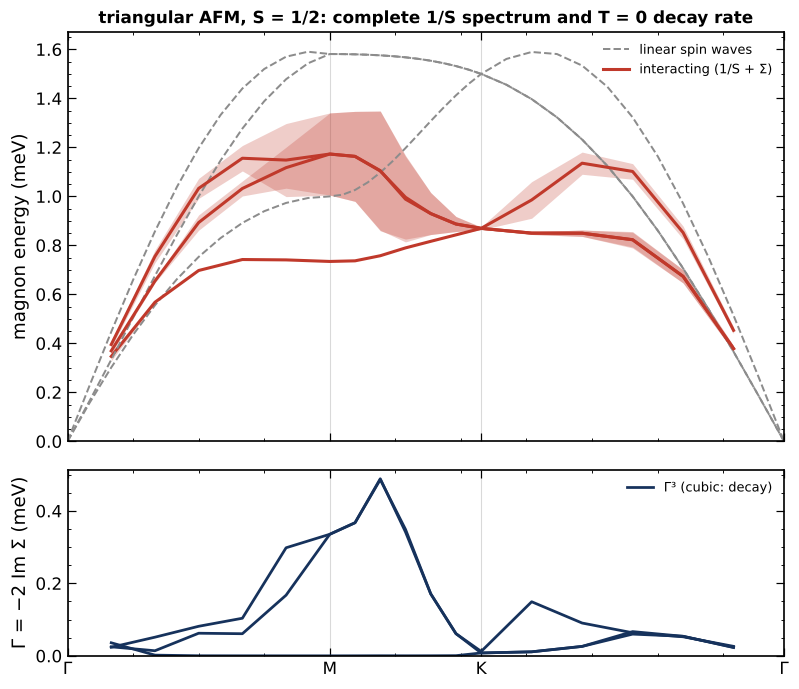

In [6]:
d = "../examples/vasp/Triangular_120AFM_INCAR"
p = read_poscar(f"{d}/POSCAR"); mags = np.array(read_incar(f"{d}/INCAR")["magmom"]).reshape(-1, 3)
ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], [0, 0, 0]))
from symphase.magint import analyse_interacting, plot_interacting
res = analyse_interacting(p["lattice"], p["frac"], [0, 0, 0], ["Cr"] * 3, mags, ds.rotations, ds.translations, T=0.0,
                          grid=(24, 24, 1), n_per=12, cubic=True, sigma=0.04, every=2, J=[1.0], spin=0.5, rmax=3.1)
plot_interacting(res, title="triangular AFM, S = 1/2: complete 1/S spectrum and T = 0 decay rate");

## 4. Field-induced spontaneous magnon decay (square-lattice AFM)

In a field the spins cant, cubic terms appear, and above $h^*\approx0.76\,h_s$ magnons decay into two magnons at $T=0$
(Zhitomirsky, Chernyshev 1999). Maximum decay rate along Γ–X:

h/h_s = 0.60: max Γ³ = 0.013 meV


h/h_s = 0.68: max Γ³ = 0.049 meV


h/h_s = 0.72: max Γ³ = 0.172 meV


h/h_s = 0.76: max Γ³ = 1.382 meV


h/h_s = 0.80: max Γ³ = 5.183 meV


h/h_s = 0.85: max Γ³ = 2.084 meV


h/h_s = 0.90: max Γ³ = 1.372 meV


Text(0.5, 1.0, 'onset of magnon decay')

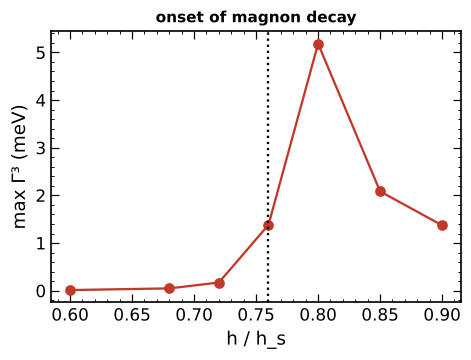

In [7]:
hrs = [0.6, 0.68, 0.72, 0.76, 0.8, 0.85, 0.9]; gm = []
for hr in hrs:
    hfq, seq, latq = canted_square(hr)
    qq, _, _ = make_path(latq, [("Γ", (0, 0, 0)), ("X", (0.5, 0, 0))], 8)
    gm.append(max(seq.onshell(x, 0.0, (24, 24, 1), sigma=0.04, tadpole=False)["gamma3"].max() for x in qq[1:]))
    print(f"h/h_s = {hr:.2f}: max Γ³ = {gm[-1]:.3f} meV")
fig, ax = plt.subplots(figsize=(4.8, 3.2)); ax.plot(hrs, gm, "o-", color="#c0392b"); ax.axvline(0.76, ls=":", color="k")
ax.set_xlabel("h / h_s"); ax.set_ylabel("max Γ³ (meV)"); ax.set_title("onset of magnon decay", fontsize=10)

Below threshold the small values are smearing tails: they shrink when the grid is refined and σ reduced.

## 5. Four-magnon damping at finite temperature (square-lattice ferromagnet)

No decays at $T=0$ (number-conserving vertex); thermal $2\leftrightarrow2$ scattering gives a damping that grows steeply with $T$ and is
suppressed at small $k$ (on-shell vertex → 0, Dyson):

In [8]:
fm, sf = square_fm()
kfs = [0.1, 0.2, 0.3, 0.4]
for T in (0.0, 20.0, 40.0):
    g4 = [sf.onshell(np.array([kf * 2 * np.pi / a, 0, 0]), T, (12, 12, 1), cubic=False, quartic=True, eta=0.2, sigma=0.2)["gamma4"][0]
          for kf in kfs]
    print(f"T = {T:4.0f} K: Γ⁴ =", np.round(g4, 4), "meV")

T =    0 K: Γ⁴ = [0. 0. 0. 0.] meV


T =   20 K: Γ⁴ = [0.0107 0.0468 0.1142 0.1636] meV


T =   40 K: Γ⁴ = [0.0816 0.3721 0.9109 1.3   ] meV


## 6. Spectral function of a decaying magnon

The pole representation works with the spectral-function helpers of tutorial 20:

Text(0.5, 1.0, 'cubic self-energy: broadened, shifted magnon')

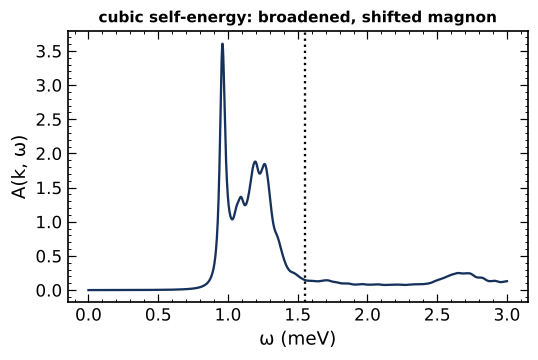

In [9]:
from symphase.magdamp import MagnonPhononVertex as MPV
k = np.array([2 * np.pi / (3 * a) * 1.2, 0.0, 0])
e0, W, E = se.cubic_poles(k, 2, 0.0, (36, 36, 1))
ws = np.linspace(0, 3, 1500); sig = MPV.self_energy(W, E, ws, 0.03)
A = MPV.spectral(e0, sig, ws, 1e-3)
fig, ax = plt.subplots(figsize=(5.4, 3.2)); ax.plot(ws, A, color="#16325c"); ax.axvline(e0, ls=":", color="k")
ax.set_xlabel("ω (meV)"); ax.set_ylabel("A(k, ω)"); ax.set_title("cubic self-energy: broadened, shifted magnon", fontsize=10)

## Command line
```bash
cd examples/vasp/Triangular_120AFM_INCAR
symphase magnons --J 1 --spin 0.5 --rmax 3.1 --hf 0 --hf-grid 30 30 --cubic --se-sigma 0.03 --nq 16 --se-every 2
symphase magnons ... --hf 40 --damping4 --grid4 12 12          # four-magnon damping Γ⁴
```
Output: `*_hf.png` (bands with Γ shading + linewidth panel), `*_selfenergy.dat` (ε, δε_HF, Re Σ³, Σ_tad, Re Σ⁴, ω, Γ³, Γ⁴).
Limits: on-shell perturbation theory (no self-consistency near decay thresholds); single-ion anisotropy enters the quartic terms at harmonic
level only; Goldstone modes exactly at their zero are excluded. Continue with **25_quiz_nonlinear_spin_waves.ipynb**.